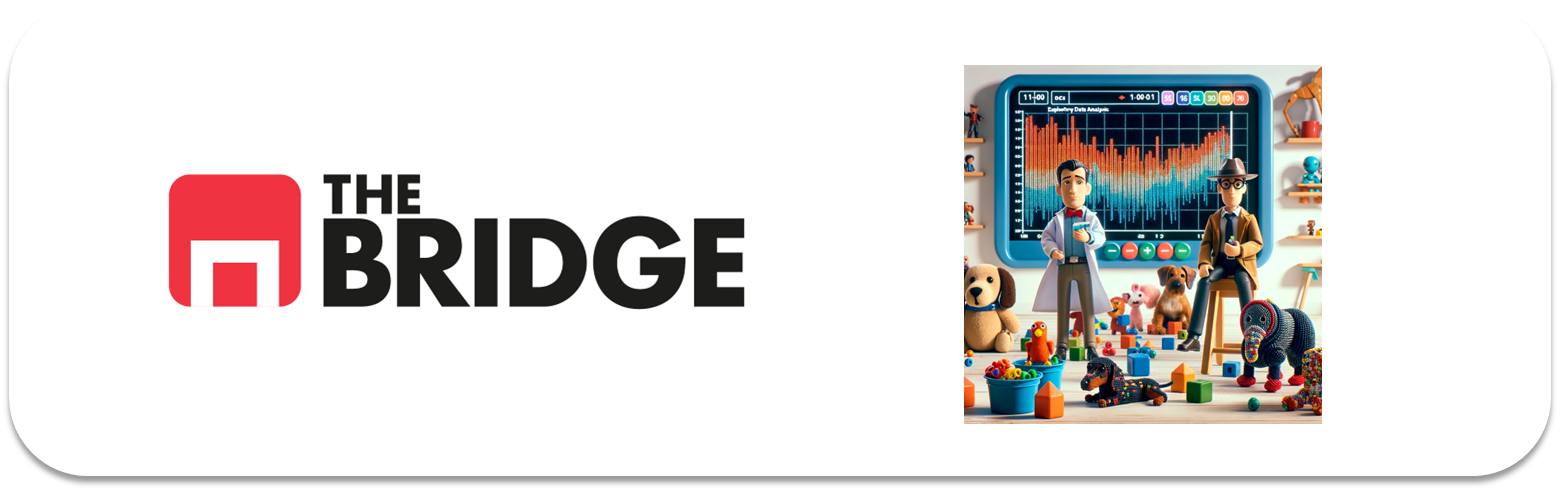

## PRACTICA OBLIGATORIA: ANÁLISIS MULTIVARIANTE

### Ejercicio 0


Importa los paquetes y módulos que necesites a lo largo del notebook

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

## #1 TITANIC

### #1.1

Carga en un dataframe el dataset del titanic, que está en la ruta "./data/titanic.csv".

In [3]:
df_titanic = sns.load_dataset("titanic")

In [4]:
df_titanic

,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
886,0,2,male,27.0,0,0,13.0000,S,Second,man,True,NaN,Southampton,no,True
887,1,1,female,19.0,0,0,30.0000,S,First,woman,False,B,Southampton,yes,True
888,0,3,female,NaN,1,2,23.4500,S,Third,woman,False,NaN,Southampton,no,False
889,1,1,male,26.0,0,0,30.0000,C,First,man,True,C,Cherbourg,yes,True


### #1.2

Deshazte de las columnas "deck", "survived", "pclass" y "embarked" porque no las emplearemos, la primera por su cantidad de nulos y el resto porque son variantes de otras que ya existen y cuyos valores resultan más expresivos a la hora de hacer un análisis. 

In [5]:
df_titanic = df_titanic.drop(columns=["deck", "survived", "pclass"])

### #1.3

Suma las columnas "parch" y "sibsp" para tener el número de parientes de cada pasajero, guarda el resultado en otra columna "family_members", luego deshazte de "parch" y "sibsp"

In [6]:
df_titanic.parch + df_titanic.sibsp

0      1
1      1
2      0
3      1
4      0
      ..
886    0
887    0
888    3
889    0
890    0
Length: 891, dtype: int64

### #1.4

Imputa la moda a los valores nulos de "embark_town"

In [7]:
df_titanic.embark_town = df_titanic.embark_town.fillna(df_titanic.embark_town.mode()[0])

### #1.5

Imputa la media a los valores faltantes de "age", si quieres puedes hacer algo más preciso (por ejemplo considerando además la columna "who")

In [8]:
df_titanic["age"] = df_titanic["age"].replace(["", " ", "?", "unknown"], np.nan)

df_titanic["age"] = df_titanic["age"].fillna(df_titanic["age"].mean())

### 1.6

Realiza los análisis bivariantes o multivariantes que necesites, así como los test de hipótesis necesarios para contestar a las siguientes preguntas. Nota: utiliza la variable "alive" para saber si un pasajero sobrevivió o no:

1. En términos absolutos, ¿sobrevivieron más hombres, mujeres o niños? ¿Y en términos relativos? ¿Existe alguna relación estadísticamente significativa entre el sexo y la supervivencia en el Titanic?¿Y entre ser adulto o ser niño?

2. En términos absolutos, ¿de que clase sobrevivieron más pasajeros?¿ Y en términos relativos? ¿Existe alguna relación estadísticamente significativa entre la clase en la que se viajaba y la supervivencia?

3. ¿De qué ciudad sobrevivieron más personas?¿Y porcentualmente de que ciudad sobrevivieron más personas? ¿Hay alguna relación estadística significativa entre haber embarcado en una de las tres ciudades y haber sobrevivido o fallecido?

4. ¿Qué relación hay entre el precio del pasaje y la supervivencia/fallecimiento?

5. Existen pasajero que no pagaron el billete, ¿podrías explicar por qué? ¿Qué ocurrió con la persona que más dinero se dejó?

6. Existe alguna relación entre el dinero pagado, la ciudad de embarque y la superviviencia/fallecimiento. No necesitas aplicar ningún test, muestralo numérica o visualmente.

7. Ahondando en la relación entre sobrevivir o fallecer, la clase en la que se viajó y la edad de los pasajeros. ¿Qué agrupación de las dos variables (clase y edad) sobrevivió más en términos absolutos y en términos relativos?

8. Finalmente, muestra las posibles relaciones entre edad, coste del billete y supervivencia/fallecimiento. ¿Qué puedes decir al respecto?

In [9]:
df_titanic.columns

Index(['sex', 'age', 'sibsp', 'parch', 'fare', 'embarked', 'class', 'who',
       'adult_male', 'embark_town', 'alive', 'alone'],
      dtype='str')

### 1. Supervivencia en función del sexo y la edad

In [10]:
hombres = ((df_titanic.alive == "yes") & (df_titanic.adult_male == True)).sum()
mujeres = ((df_titanic.alive == "yes") & (df_titanic.age > 18) & (df_titanic.sex == "female")).sum()
niños = ((df_titanic.alive == "yes") & (df_titanic.age < 18)).sum()

if hombres < niños:
    if niños < mujeres:
        print("En términos absolutos, sobrevivieron más mujeres")
    else:
        print("En términos absolutos, sobrevivieron más niños")
else:
    print("En términos absolutos, sobrevivieron más hombres")

En términos absolutos, sobrevivieron más hombres


In [11]:
hombres = ((df_titanic.alive == "yes") & (df_titanic.adult_male == True)).sum() / (df_titanic.adult_male == True).sum()
mujeres = ((df_titanic.alive == "yes") & (df_titanic.age > 18) & (df_titanic.sex == "female")).sum() / ((df_titanic.age > 18) & (df_titanic.sex == "female")).sum()
niños = ((df_titanic.alive == "yes") & (df_titanic.age < 18)).sum() / (df_titanic.age < 18).sum()

if hombres < niños:
    if niños < mujeres:
        print("En términos relativos, sobrevivieron más mujeres")
    else:
        print("En términos relativos, sobrevivieron más niños")
else:
    print("En términos relativos, sobrevivieron más hombres")

En términos relativos, sobrevivieron más mujeres


In [12]:
hombres = ((df_titanic.alive == "yes") & (df_titanic.adult_male == True)).sum() / (df_titanic.adult_male == True).sum()
mujeres = ((df_titanic.alive == "yes") & (df_titanic.age > 18) & (df_titanic.sex == "female")).sum()/ ((df_titanic.age > 18) & (df_titanic.sex == "female")).sum()
print(f"El porcentaje de hombres que sobreviven es del {round(hombres*100)}%; mientras que el de mujeres es del {round(mujeres*100)}%. Por tanto, es razonable asumir que el sexo está ligado a la supervivencia.")

El porcentaje de hombres que sobreviven es del 16%; mientras que el de mujeres es del 76%. Por tanto, es razonable asumir que el sexo está ligado a la supervivencia.


In [13]:
niños = ((df_titanic.alive == "yes") & (df_titanic.age < 18)).sum() / (df_titanic.age < 18).sum()
adultos = ((df_titanic.alive == "yes") & (df_titanic.age > 18)).sum()/ (df_titanic.age > 18).sum()
print(f"El porcentaje de niños que sobreviven es del {round(niños*100)}%; mientras que el de adultos es del {round(adultos*100)}%. Por tanto, es posible asumir que la edad está un poco ligada a la supervivencia.")

El porcentaje de niños que sobreviven es del 54%; mientras que el de adultos es del 36%. Por tanto, es posible asumir que la edad está un poco ligada a la supervivencia.


### 2. Supervivencia en función de la clase

In [14]:
primera = ((df_titanic.alive == "yes") & (df_titanic["class"] == "First")).sum()
segunda = ((df_titanic.alive == "yes") & (df_titanic["class"] == "Second")).sum()
tercera = ((df_titanic.alive == "yes") & (df_titanic["class"] == "Third")).sum()

if primera < segunda:
    if segunda < tercera:
        print("En términos absolutos, sobrevivieron más personas de tercera clase")
    else:
        print("En términos absolutos, sobrevivieron más personas de segunda clase")
else:
    print("En términos absolutos, sobrevivieron más personas de primera clase")

En términos absolutos, sobrevivieron más personas de primera clase


In [15]:
primera = ((df_titanic.alive == "yes") & (df_titanic["class"] == "First")).sum() / (df_titanic["class"] == "First").sum()
segunda = ((df_titanic.alive == "yes") & (df_titanic["class"] == "Second")).sum() / (df_titanic["class"] == "Second").sum()
tercera = ((df_titanic.alive == "yes") & (df_titanic["class"] == "Third")).sum() / (df_titanic["class"] == "Third").sum()

if primera < segunda:
    if segunda < tercera:
        print("En términos relativos, sobrevivieron más personas de tercera clase")
    else:
        print("En términos relativos, sobrevivieron más personas de segunda clase")
else:
    print("En términos relativos, sobrevivieron más personas de primera clase")

En términos relativos, sobrevivieron más personas de primera clase


In [16]:
primera = ((df_titanic.alive == "yes") & (df_titanic["class"] == "First")).sum() / (df_titanic["class"] == "First").sum()
segunda = ((df_titanic.alive == "yes") & (df_titanic["class"] == "Second")).sum() / (df_titanic["class"] == "Second").sum()
tercera = ((df_titanic.alive == "yes") & (df_titanic["class"] == "Third")).sum() / (df_titanic["class"] == "Third").sum()
print(f"El porcentaje de primera clase que sobrevive es del {round(primera*100)}%; mientras que el de segunda es del {round(segunda*100)}% y el de tercera es del {round(tercera*100)}%. Por tanto, es razonable asumir que la clase está ligada a la supervivencia.")

El porcentaje de primera clase que sobrevive es del 63%; mientras que el de segunda es del 47% y el de tercera es del 24%. Por tanto, es razonable asumir que la clase está ligada a la supervivencia.


### 3. Supervivencia en función del puerto

In [17]:
df_titanic.embark_town.unique()

<StringArray>
['Southampton', 'Cherbourg', 'Queenstown']
Length: 3, dtype: str

In [18]:
Southampton = ((df_titanic.alive == "yes") & (df_titanic.embark_town == "Southampton")).sum()
Cherbourg = ((df_titanic.alive == "yes") & (df_titanic.embark_town == "Cherbourg")).sum()
Queenstown = ((df_titanic.alive == "yes") & (df_titanic.embark_town == "Queenstown")).sum()

if Southampton < Cherbourg:
    if Cherbourg < Queenstown:
        print("Hubo más supervivientes de Queenstown")
    else:
        print("Hubo más supervivientes de Cherbourg")
else:
    print("Hubo más supervivientes de Southampton")

Hubo más supervivientes de Southampton


In [19]:
Southampton = ((df_titanic.alive == "yes") & (df_titanic.embark_town == "Southampton")).sum()
Cherbourg = ((df_titanic.alive == "yes") & (df_titanic.embark_town == "Cherbourg")).sum()
Queenstown = ((df_titanic.alive == "yes") & (df_titanic.embark_town == "Queenstown")).sum()
print(f"La cantidad de supervivientes que embarcaron en Southampton es {Southampton}; mientras en Cherbourg embarcaron {Cherbourg} y en Queenstown, {Queenstown} supervivientes. Por tanto, es razonable asumir que el puerto no es determinante para la supervivencia.")

La cantidad de supervivientes que embarcaron en Southampton es 219; mientras en Cherbourg embarcaron 93 y en Queenstown, 30 supervivientes. Por tanto, es razonable asumir que el puerto no es determinante para la supervivencia.


In [20]:
Southampton = ((df_titanic.alive == "yes") & (df_titanic.embark_town == "Southampton")).sum() / (df_titanic.embark_town == "Southampton").sum()
Cherbourg = ((df_titanic.alive == "yes") & (df_titanic.embark_town == "Cherbourg")).sum() / (df_titanic.embark_town == "Cherbourg").sum()
Queenstown = ((df_titanic.alive == "yes") & (df_titanic.embark_town == "Queenstown")).sum() / (df_titanic.embark_town == "Queenstown").sum()
print(f"El porcentaje de supervivientes que embarcaron en Southampton es del {round(Southampton*100)}%; mientras que el de supervivientes que embarcaron en Cherbourg es {round(Cherbourg*100)}% y el de los que embarcaron en Queenstown es del {round(Queenstown*100)}%. Por tanto, es razonable asumir que el puerto no es determinante para la supervivencia.")

El porcentaje de supervivientes que embarcaron en Southampton es del 34%; mientras que el de supervivientes que embarcaron en Cherbourg es 55% y el de los que embarcaron en Queenstown es del 39%. Por tanto, es razonable asumir que el puerto no es determinante para la supervivencia.



### 4. Supervivencia en función del precio del pasaje.

In [21]:
df_titanic[(df_titanic.alive == "yes")].fare.describe()
#print(f"El porcentaje de primera clase que sobrevive es del {round(primera*100)}%; mientras que el de segunda es del {round(segunda*100)}% y el de tercera es del {round(tercera*100)}%. Por tanto, es razonable asumir que la clase está ligada a la supervivencia.")

count    342.000000
mean      48.395408
std       66.596998
min        0.000000
25%       12.475000
50%       26.000000
75%       57.000000
max      512.329200
Name: fare, dtype: float64

In [22]:
df_titanic[(df_titanic.alive == "no")].fare.describe()

count    549.000000
mean      22.117887
std       31.388207
min        0.000000
25%        7.854200
50%       10.500000
75%       26.000000
max      263.000000
Name: fare, dtype: float64

In [23]:
print(f"Los supervivientes pagaron unas {round(df_titanic[(df_titanic.alive == "yes")].fare.mean() / df_titanic[(df_titanic.alive == "no")].fare.mean())} veces más por el billete")

Los supervivientes pagaron unas 2 veces más por el billete


In [24]:
print(f"Los supervivientes pagaron billetes que variaban unas {round(df_titanic[(df_titanic.alive == "yes")].fare.std() / df_titanic[(df_titanic.alive == "no")].fare.std())} veces más de precio entre sí que los billetes de los que no sobrevivieron")

Los supervivientes pagaron billetes que variaban unas 2 veces más de precio entre sí que los billetes de los que no sobrevivieron


### 5. Máximo y mínimo del precio de los billetes

In [25]:
df_titanic[df_titanic.fare == df_titanic.fare.min()] # billetes de trabajadores

,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,embark_town,alive,alone
179,male,36.000000,0,0,0.0,S,Third,man,True,Southampton,no,True
263,male,40.000000,0,0,0.0,S,First,man,True,Southampton,no,True
271,male,25.000000,0,0,0.0,S,Third,man,True,Southampton,yes,True
277,male,29.699118,0,0,0.0,S,Second,man,True,Southampton,no,True
302,male,19.000000,0,0,0.0,S,Third,man,True,Southampton,no,True
413,male,29.699118,0,0,0.0,S,Second,man,True,Southampton,no,True
466,male,29.699118,0,0,0.0,S,Second,man,True,Southampton,no,True
481,male,29.699118,0,0,0.0,S,Second,man,True,Southampton,no,True
597,male,49.000000,0,0,0.0,S,Third,man,True,Southampton,no,True
633,male,29.699118,0,0,0.0,S,First,man,True,Southampton,no,True


In [26]:
df_titanic[df_titanic.fare == df_titanic.fare.max()].alive

258    yes
679    yes
737    yes
Name: alive, dtype: str

### 6. Supervivencia en función del precio del billete y la ciudad de embarque

<Axes: xlabel='embark_town', ylabel='fare'>

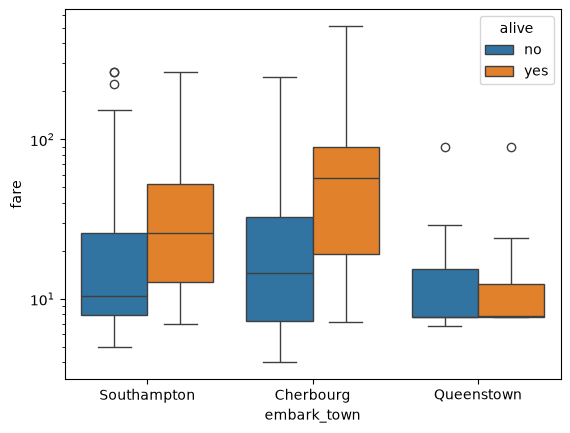

In [27]:
sns.boxplot(data=df_titanic, x="embark_town", y="fare", hue="alive", log_scale=True)

<Axes: xlabel='embark_town', ylabel='fare'>

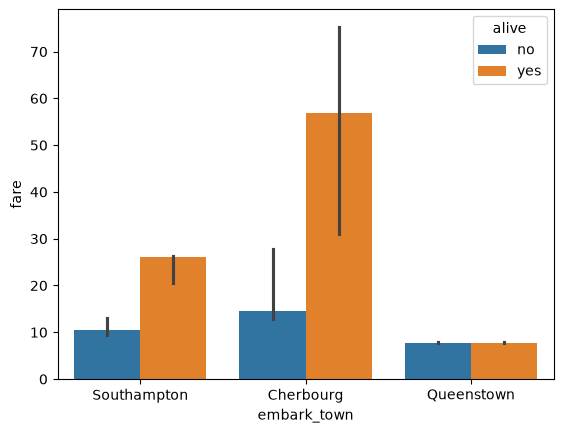

In [28]:
sns.barplot(data=df_titanic, x="embark_town", y="fare", hue="alive", estimator="median")

### 7. Supervivencia en función de clase y edad
Ahondando en la relación entre sobrevivir o fallecer, la clase en la que se viajó y la edad de los pasajeros. ¿Qué agrupación de las dos variables (clase y edad) sobrevivió más en términos absolutos y en términos relativos?

In [60]:
tabla = df_titanic.pivot_table(index="class", columns="alive", values="age", aggfunc="median")
tabla

alive,no,yes
class,,
First,38.500000,33.5
Second,30.000000,28.0
Third,29.699118,27.0


<Axes: xlabel='alive', ylabel='class'>

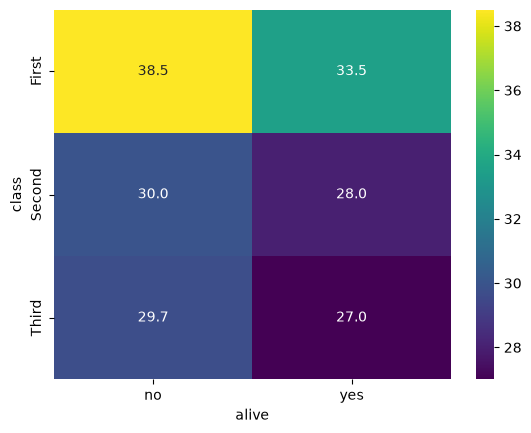

In [ ]:
sns.heatmap(tabla, annot=True, fmt=".1f", cmap="viridis")

In [30]:
df_titanic["grupo_edad"] = pd.cut(df_titanic["age"], bins=[0, 12, 18, 35, 60, 80])
df_titanic.groupby(["class", "grupo_edad"])["alive"].value_counts().unstack(fill_value=0)

alive               no  yes
class  grupo_edad          
First  (0, 12]       1    3
       (12, 18]      1   11
       (18, 35]     32   64
       (35, 60]     35   55
       (60, 80]     11    3
Second (0, 12]       0   17
       (12, 18]      6    6
       (18, 35]     60   45
       (35, 60]     29   18
       (60, 80]      2    1
Third  (0, 12]      28   20
       (12, 18]     33   13
       (18, 35]    254   80
       (35, 60]     53    5
       (60, 80]      4    1

### 8. Supervivencia en función de la edad y el precio del billete.

In [31]:
df_titanic["grupo_edad"] = pd.cut(df_titanic["age"], bins=[0, 12, 18, 35, 60, 80])
df_titanic["grupo_precio"] = pd.cut(df_titanic["fare"], bins=[0, 5, 10, 100, 300, 600])
df_titanic.groupby(["grupo_precio", "grupo_edad"])["alive"].value_counts().unstack(fill_value=0)

alive                     no  yes
grupo_precio grupo_edad          
(0, 5]       (18, 35]      2    0
(5, 10]      (0, 12]       0    1
             (12, 18]     20   11
             (18, 35]    196   50
             (35, 60]     33    3
             (60, 80]      4    1
(10, 100]    (0, 12]      28   37
             (12, 18]     19   13
             (18, 35]    132  123
             (35, 60]     75   59
             (60, 80]     12    4
(100, 300]   (0, 12]       1    2
             (12, 18]      1    6
             (18, 35]      7   13
             (35, 60]      4   15
             (60, 80]      1    0
(300, 600]   (18, 35]      0    2
             (35, 60]      0    1

## #2 Viajes

El objetivo en este caso no es tanto hacer un montón de análisis sino entender cómo de un dataset podemos obtener preguntas o hipótesis interesantes (si las hay)

### #2.1 

Carga el dataset de viajes del mes de junio. Repite el análisis bivariante entre las variables "Aircompany" e "Ingresos", mostrando previamente los viajes por compañía aérea. ¿Qué situación llamativa nos surgió? (Ten en cuenta que somos el departamenteo de DataScience de TabarAir)

In [41]:
df_viajes = pd.read_csv("../data/dataset_viajes_A.csv")
df_viajes                                                                                                                    

,aircompany,origen,destino,distancia,avion,con_escala,consumo_kg,duracion,ingresos,id_vuelo,mes
0,Airnar,París,Ginebra,411,Boeing 737,False,1028.691900,51,14232.65,Air_PaGi_10737,Jun23
1,FlyQ,Bali,Roma,12738,Boeing 737,True,33479.132544,1167,468527.19,Fly_BaRo_10737,Jun23
2,TabarAir,Ginebra,Los Angeles,9103,Airbus A380,False,109439.907200,626,584789.19,Tab_GiLo_11380,Jun23
3,MoldaviAir,París,Cincinnati,6370,Boeing 737,False,17027.010000,503,233342.51,Mol_PaCi_10737,Jun23
4,TabarAir,Cincinnati,Roma,7480,Boeing 747,False,86115.744000,518,438535.07,Tab_CiRo_10747,Jun23
...,...,...,...,...,...,...,...,...,...,...,...
595,PamPangea,Bali,Londres,12553,Boeing 737,True,33310.138680,1153,442668.52,Pam_BaLo_10737,Jun23
596,Airnar,Cádiz,París,1447,Airbus A380,False,17229.139600,116,87307.63,Air_CaPa_11380,Jun23
597,Airnar,Los Angeles,Cádiz,9373,Boeing 737,False,23231.917800,731,339943.47,Air_LoCa_10737,Jun23
598,FlyQ,Barcelona,Bali,13058,Boeing 747,True,144766.211200,1070,752212.98,Fly_BaBa_10747,Jun23


In [43]:
df_viajes.aircompany.unique()

<StringArray>
['Airnar', 'FlyQ', 'TabarAir', 'MoldaviAir', 'PamPangea']
Length: 5, dtype: str

In [50]:
df_viajes.ingresos.describe()

count    6.000000e+02
mean     4.187689e+05
std      3.182858e+05
min      1.179785e+04
25%      1.627668e+05
50%      3.754817e+05
75%      6.188420e+05
max      1.295516e+06
Name: ingresos, dtype: float64

In [52]:
df_viajes.groupby("aircompany").ingresos.describe()

,count,mean,std,min,25%,50%,75%,max
aircompany,,,,,,,,
Airnar,100.0,405293.978200,269583.848420,14232.65,185270.6000,396764.220,608356.1225,958617.02
FlyQ,108.0,401619.008056,295633.712828,23498.34,237556.9525,366970.685,473901.4325,1081702.91
MoldaviAir,133.0,548077.209098,374577.838426,11797.85,178872.9000,532426.220,794055.4100,1295515.83
PamPangea,117.0,478417.048718,364458.092328,12383.21,163124.5300,442668.520,763079.0200,1083591.01
TabarAir,142.0,271042.230282,177006.035877,24289.53,95620.5075,258379.745,398147.1925,623089.41


La compañía MoldaviAir es la que más ha ingresado, a pesar de haber realizado menos viajes que la compañía que menos ha ingresado, que es TabarAir.

### #2.2

Repite el análisis multivariante entre "ingresos","distancias" y "consumo_kg". ¿Qué veíamos que parecía también muy prometedor?

<Axes: xlabel='distancia', ylabel='consumo_kg'>

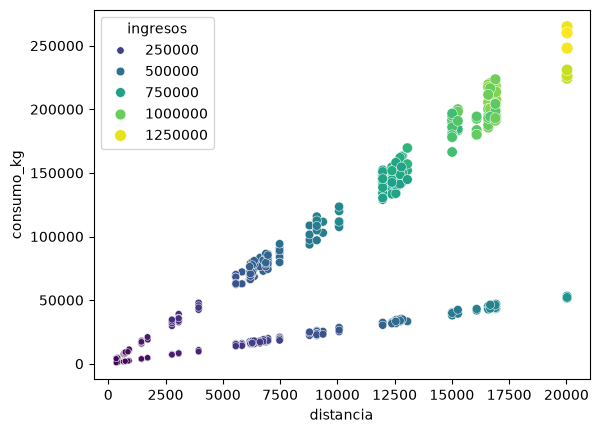

In [106]:
sns.scatterplot(data=df_viajes, x="distancia", y="consumo_kg", hue="ingresos", size="ingresos", palette="viridis")

Se aprecia que, a pesar de que el consumo crece al crecer la distancia, los ingresos crecen más con el consumo que con la distancia.

<Axes: xlabel='ingresos', ylabel='consumo_kg'>

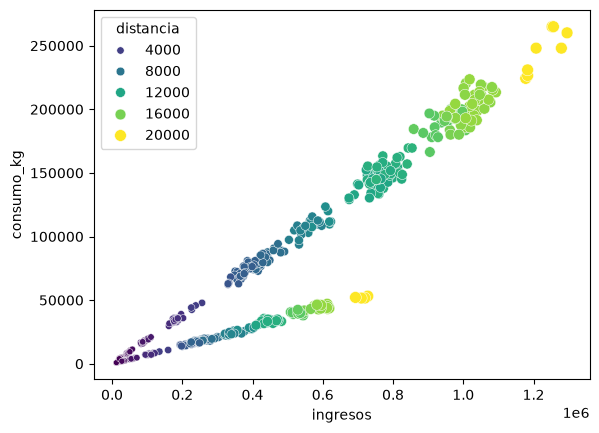

In [105]:
sns.scatterplot(data=df_viajes, x="ingresos", y="consumo_kg", hue="distancia", size="distancia", palette="viridis")

<Axes: >

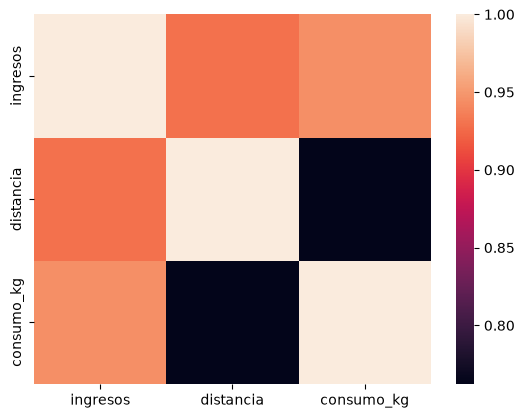

In [83]:
sns.heatmap(df_viajes[["ingresos", "distancia", "consumo_kg"]].corr())

Los ingresos dependen bastante del consumo y en segundo plano de la distancia; mientras que el consumo depende poco de la distancia.

### #2.3

Crea una variable categorica "cat_vuelo" a partir de distancias, escoge los rangos de las categorías basándote en la distribución de valores de "distancia" (sugerencia entre 3 y 4 categorías). Extra: Realiza ahora otra vez el análisis multivariante "cat_vuelo", "ingresos", "consumo_kg". ¿Ves algo diferente?

<Axes: xlabel='distancia', ylabel='Count'>

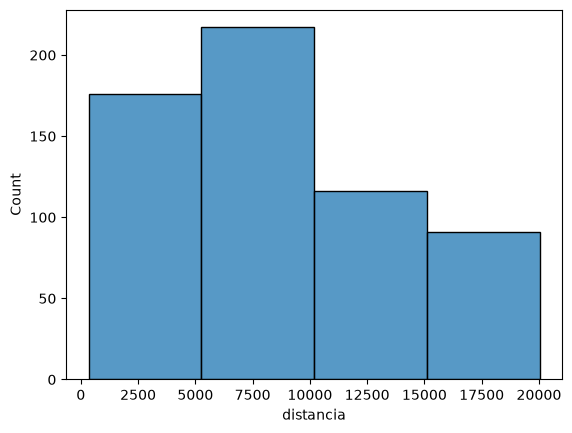

In [95]:
sns.histplot(data = df_viajes, x = "distancia", bins = 4)

In [103]:
df_viajes["cat_vuelo"] = pd.cut(df_viajes["distancia"], bins=[0, 5000, 10000, 15000, 20000])

<Axes: xlabel='ingresos', ylabel='consumo_kg'>

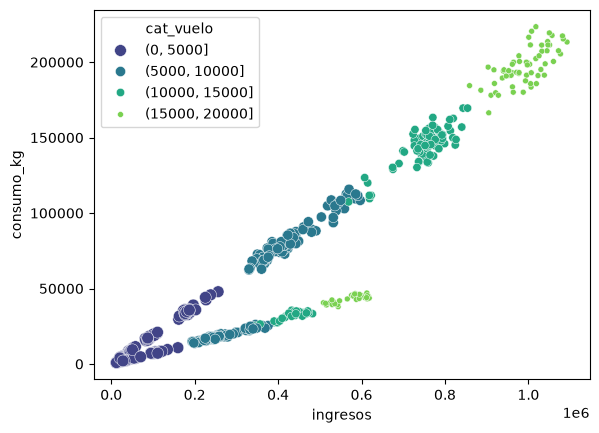

In [104]:
sns.scatterplot(data=df_viajes, x="ingresos", y="consumo_kg", hue="cat_vuelo", size="cat_vuelo", palette="viridis")

No se aprecia ninguna diferencia.

In [115]:
df_viajes.ingresos.describe()

count    6.000000e+02
mean     4.187689e+05
std      3.182858e+05
min      1.179785e+04
25%      1.627668e+05
50%      3.754817e+05
75%      6.188420e+05
max      1.295516e+06
Name: ingresos, dtype: float64

<Axes: xlabel='ingresos', ylabel='Count'>

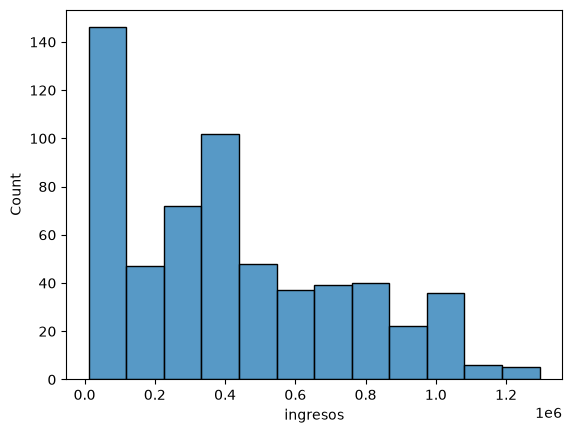

In [117]:
sns.histplot(data = df_viajes, x = "ingresos")

In [118]:
df_viajes["cat_ingresos"] = pd.cut(df_viajes["ingresos"], bins=[0, 0.2e+06, 0.4e+06, 0.6e+06, 0.8e+06, 1.0e+06, 1.2e+06])

In [119]:
tabla = df_viajes.pivot_table(index="cat_ingresos", columns="cat_vuelo", values="consumo_kg", aggfunc="mean", observed=False)

<Axes: xlabel='cat_vuelo', ylabel='cat_ingresos'>

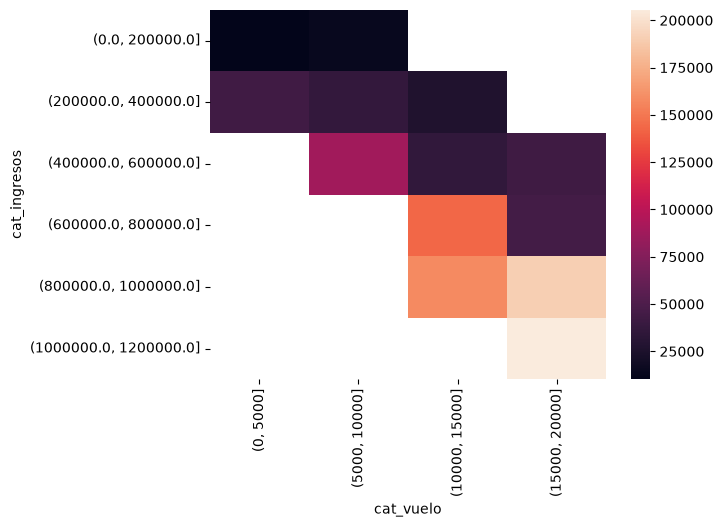

In [120]:
sns.heatmap(tabla)

### Extra:

#1 Consejos para encontrar "objetivos":

Si partes de un dataset que te parece interesante pero sin pregruntras claras, haz como hicimos con el dataset de Aviones. Describe, prioriza a ojo tus variables, realiza un análisis univariante completo, realiza un análisis bivariante ente las parejas de variables que te parecieron más intereantes. Llegados a este punto si el dataset tiene riqueza informativa, algo diferente tiene que haber aparecido (otra cosa es que sea interesante para ti :-)).  

Fíjate en lo que encontramos en el dataset de viajes: la empresa de más vuelos es la que menos ingresos tiene o la existencia clara de una línea de vuelos más eficientes en consumo que otros y otra de mayor ingresos por consumo. Lo siguiente es explorar esos puntos normalmente intentando contestar a: ¿por qué pasa?¿dónde,cuándo o cómo pasa?  

Busca esas "notas discordantes" en tu dataset, ya de por sí son mensajes del análisis. Ordénalas por importancia (importancia = impactan en ingresos, impactan en la calidad de la vida de las personas, impactan en el coste y poco más hay) e intenta entender por qué suceden esas notas discordantes, cómo solucionarlas o aprovecharlas y ya tienes objeetivos para el EDA; incluso si no encuentras respuesta siempre tendras esas notas discordantes, la conclusión de que no se puede avanzar con los datos que se tienen y los próximos pasos de encontrar más información para explicar lo que ocurre.

In [ ]:
df_viajes = pd.read_csv("../data/Marketing.csv")

#2 Contestando a las preguntas de "Viajes".

- Necesitamos identificar esas líneas eficientes, para ello crea una variable que mida el ingreso por kilogramo consumido y otra que mida el kilogramo consumido por kilómetro. Haz el análisis univariante de las mismas intentando encontrar una diferencia clara entre viajes eficientes y no eficientes (que sabemos que existe). Fija un umbral para indicar si un viaje es supereficiente o si no lo es
- Crea esa variable de eficiencia binaria de eficiencia.
- Ahora haz el análisis bivariante de esa eficiencia y las compañías aéreas (queremos ver si realmente eso explica la situación de TabarAir). 
- Para nota: Hacer los análisis multivariante por compañía, eficiencia, tipo de avión y compañía, eficiencia, destino e incluso el de compañía, eficiencia, origen, destino.
- Con todo ello deberías poder encontrar si hay respuesta a la situación de TabarAir además de poder mostrar otros datos interesantes.